# I. Pattern Mining: Supermarket Market Basket Analysis
**Dataset:** [Kaggle - Groceries Market Basket Dataset](https://www.kaggle.com/datasets/heeraldedhia/groceries-dataset)

---
### Cấu trúc bài thực hành:
1. **Khám phá dữ liệu (EDA) & Chuyển đổi sang dạng Ma trận (Matrix Format)**
2. **Thực thi thuật toán Apriori và FP-Growth với nhiều ngưỡng Support/Confidence**
3. **Đánh giá và so sánh hiệu năng (Runtime & Peak Memory Usage)**
4. **Lọc luật kết hợp có $\text{Lift} > 1$ cho chiến lược Cross-selling và Store Layout**

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

# Thêm thư mục gốc của dự án vào sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    RAW_DATA_FILE,
    OUTPUT_FIGURES_DIR,
    SUPPORT_THRESHOLDS,
    CONFIDENCE_THRESHOLDS,
    DEFAULT_MIN_SUPPORT,
    DEFAULT_MIN_CONFIDENCE,
    MIN_LIFT_THRESHOLD,
)
from src.data_processing import load_raw_data, explore_data, group_transactions, create_basket_matrix
from src.algorithms import mine_frequent_itemsets, generate_rules, evaluate_support_confidence_grid
from src.evaluation import compare_algorithms_performance
from src.business_strategy import filter_positive_lift_rules, recommend_cross_selling, recommend_store_layout
from src.visualization import (
    plot_top_items,
    plot_performance_comparison,
    plot_support_confidence_heatmap,
    plot_rules_distribution,
)

## 1. Đọc dữ liệu, EDA & Chuyển đổi sang dạng Ma trận (Matrix Format)

In [2]:
df_raw = load_raw_data(RAW_DATA_FILE)
eda_stats = explore_data(df_raw)
display(pd.DataFrame([eda_stats]))

transactions = group_transactions(df_raw)
basket_matrix = create_basket_matrix(transactions)
print(f'Kích thước ma trận nhị phân: {basket_matrix.shape}')
display(basket_matrix.head())

total_records,exact_duplicate_rows,unique_members,unique_dates,unique_items,total_transactions,avg_items_per_transaction,min_items_per_transaction,max_items_per_transaction
38765,759,3898,728,167,14963,2.54,1,10


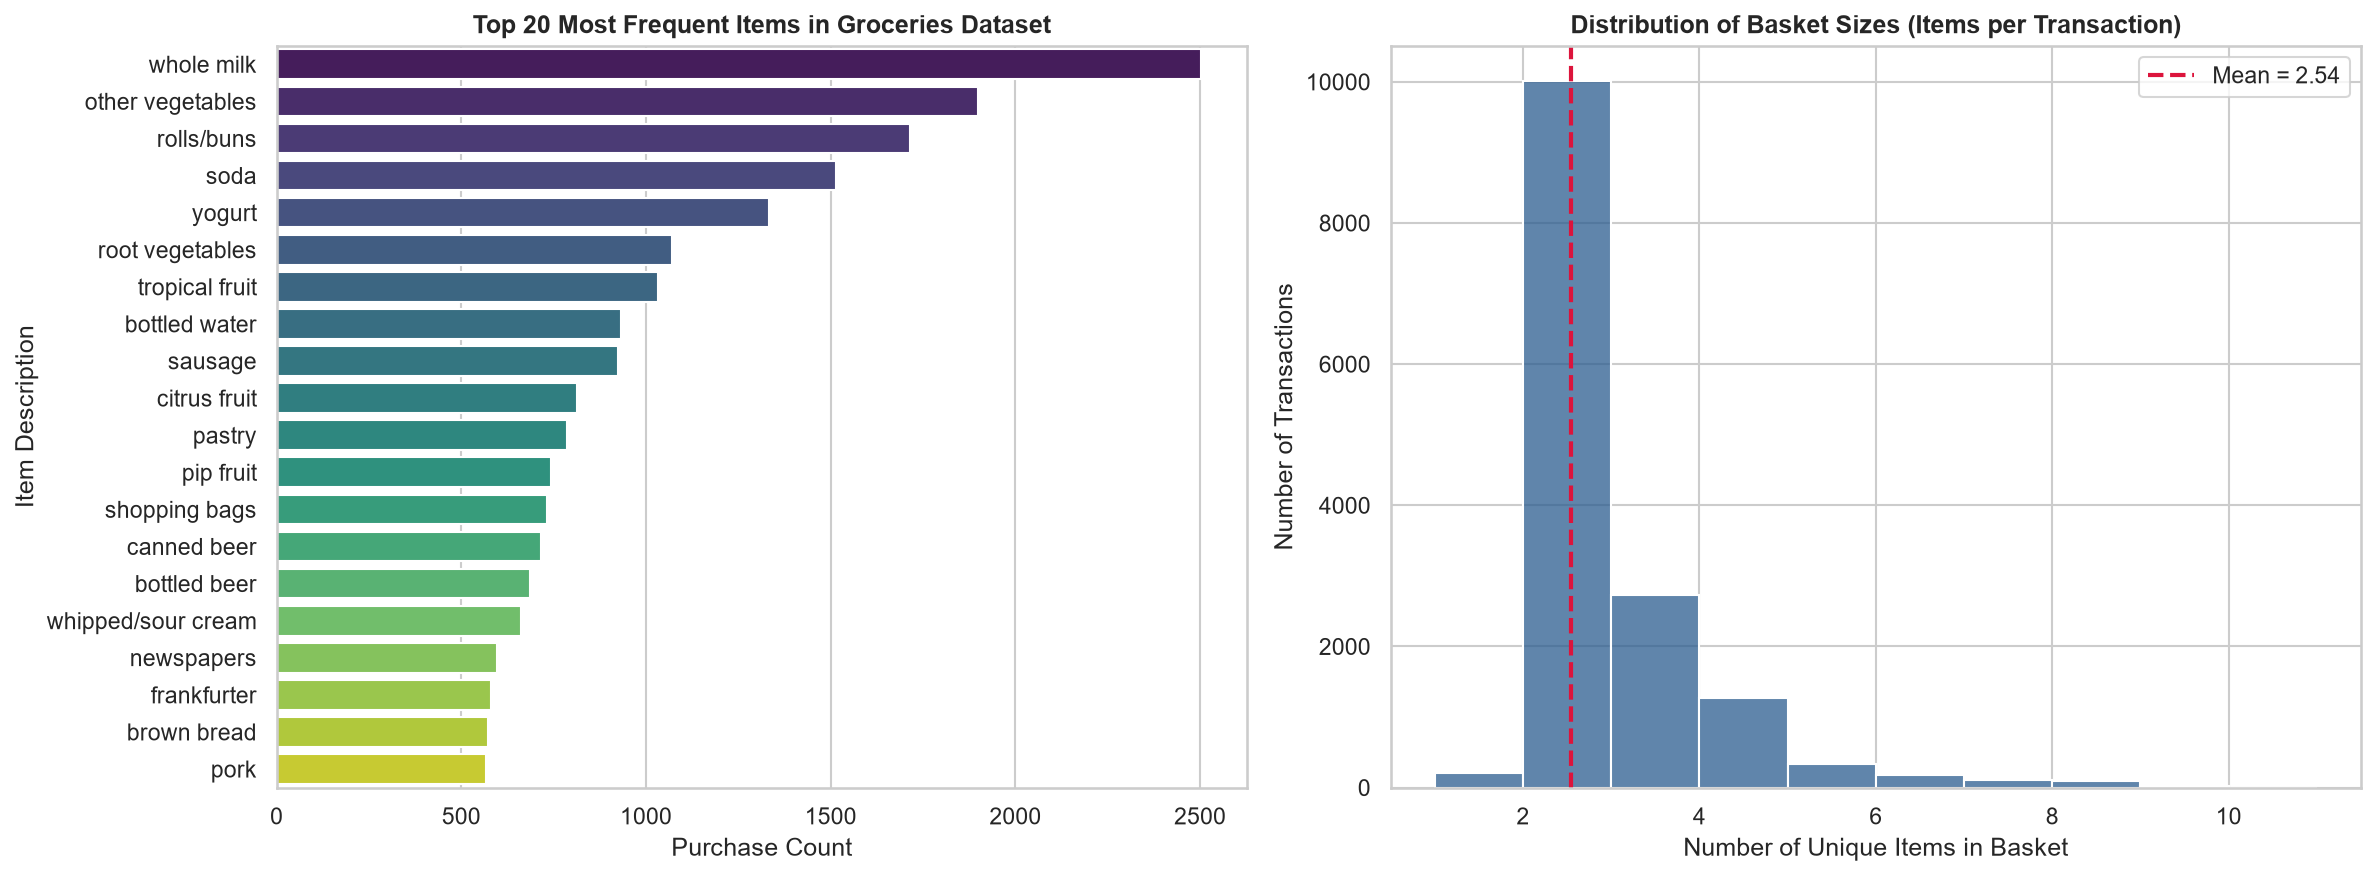

In [3]:
fig1 = plot_top_items(df_raw, OUTPUT_FIGURES_DIR)
display(Image(filename=str(fig1)))

## 2. Thực thi Apriori & FP-Growth với nhiều ngưỡng Support/Confidence

min_support,min_confidence,total_frequent_itemsets,itemsets_len_ge_2,apriori_fpgrowth_match,total_rules,rules_lift_gt_1,max_lift
0.001,0.05,750,601,True,450,94,2.1829
0.001,0.10,750,601,True,130,37,2.1829
0.001,0.15,750,601,True,10,8,1.9118
0.001,0.20,750,601,True,2,2,1.6199
0.002,0.05,330,204,True,219,24,1.4466
0.002,0.10,330,204,True,61,7,1.1161
0.002,0.15,330,204,True,2,1,1.0141
0.002,0.20,330,204,True,0,0,0.0000
0.003,0.05,216,105,True,131,13,1.2220
0.003,0.10,216,105,True,39,2,1.1161


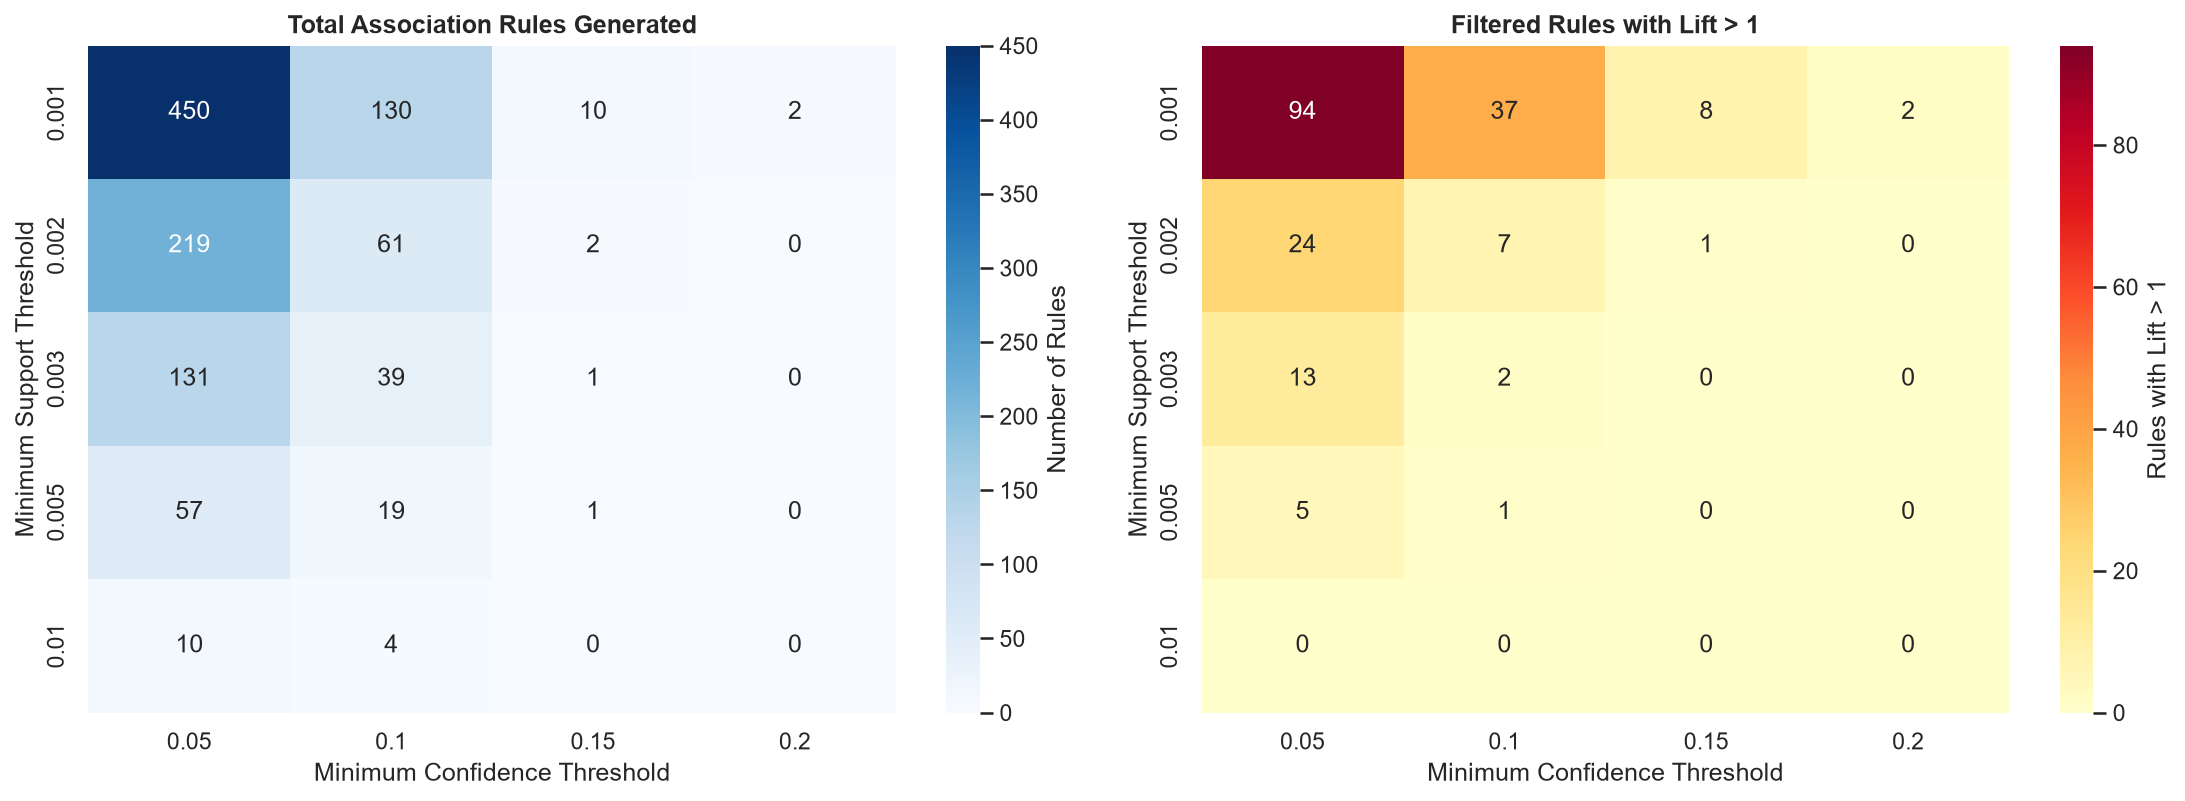

In [4]:
grid_df = evaluate_support_confidence_grid(basket_matrix, SUPPORT_THRESHOLDS, CONFIDENCE_THRESHOLDS)
display(grid_df)

fig3 = plot_support_confidence_heatmap(grid_df, OUTPUT_FIGURES_DIR)
display(Image(filename=str(fig3)))

## 3. So sánh hiệu năng thực thi (Runtime & Peak Memory Usage)

min_support,frequent_itemsets,apriori_runtime_ms,fpgrowth_runtime_ms,speedup_ratio (Apriori/FP),apriori_peak_mem_mb,fpgrowth_peak_mem_mb,memory_ratio (Apriori/FP)
0.001,750,827.36,108.04,7.66,472.316,3.531,133.76
0.002,330,364.13,83.25,4.37,337.374,3.030,111.34
0.003,216,282.39,94.16,3.00,261.573,2.820,92.76
0.005,126,145.51,77.65,1.87,167.829,2.451,68.47
0.010,69,77.31,83.40,0.93,86.460,1.870,46.24


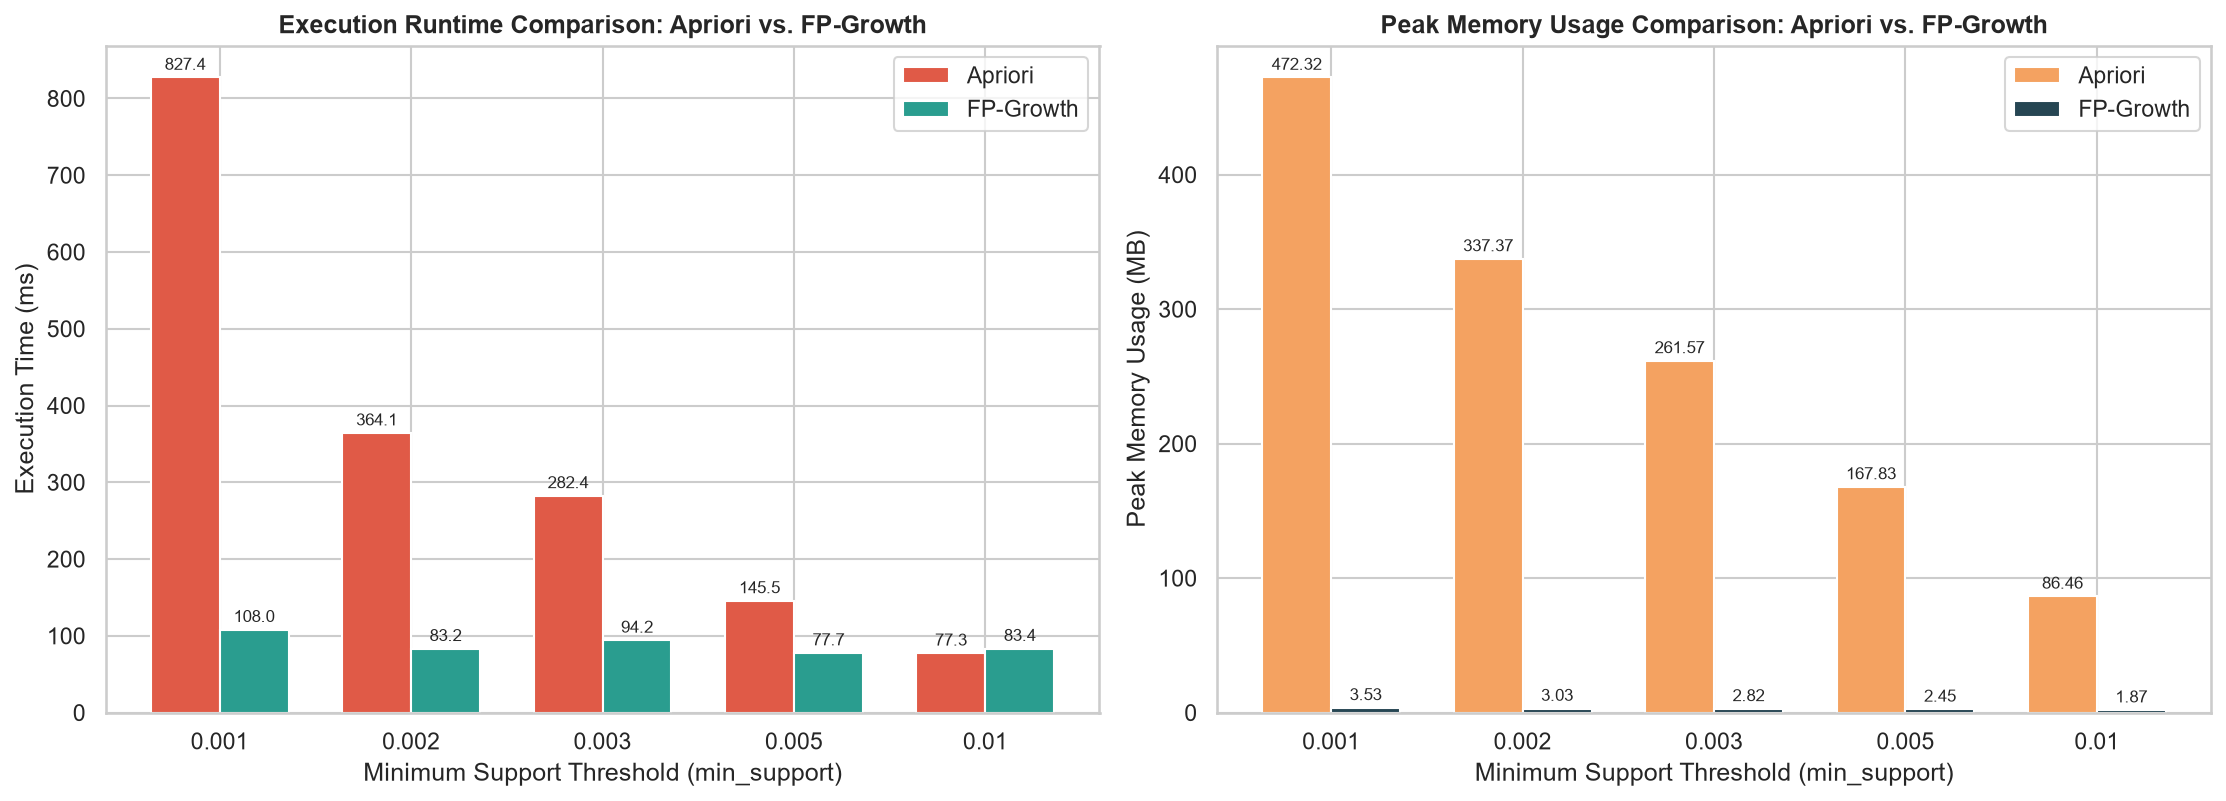

In [5]:
benchmark_df = compare_algorithms_performance(basket_matrix, SUPPORT_THRESHOLDS)
display(benchmark_df)

fig2 = plot_performance_comparison(benchmark_df, OUTPUT_FIGURES_DIR)
display(Image(filename=str(fig2)))

## 4. Lọc luật kết hợp có $\text{Lift} > 1$ cho Cross-selling và Store Layout

In [6]:
freq_items = mine_frequent_itemsets(basket_matrix, min_support=DEFAULT_MIN_SUPPORT, algorithm='fpgrowth')
all_rules = generate_rules(freq_items, min_confidence=DEFAULT_MIN_CONFIDENCE)
rules_lift_gt1 = filter_positive_lift_rules(all_rules, min_lift=MIN_LIFT_THRESHOLD)

print(f'Tổng số luật (Confidence >= {DEFAULT_MIN_CONFIDENCE}): {len(all_rules)}')
print(f'Số luật có Lift > 1: {len(rules_lift_gt1)}')
display(rules_lift_gt1[['rule_str', 'support', 'confidence', 'lift', 'leverage', 'conviction']].head(15))

rule_str,support,confidence,lift,leverage,conviction
"whole milk, yogurt -> sausage",0.001470,0.131737,2.182917,0.000797,1.082219
"sausage, whole milk -> yogurt",0.001470,0.164179,1.911760,0.000701,1.093681
"sausage, yogurt -> whole milk",0.001470,0.255814,1.619866,0.000563,1.131541
flour -> tropical fruit,0.001069,0.109589,1.617141,0.000408,1.046969
processed cheese -> root vegetables,0.001069,0.105263,1.513019,0.000363,1.039891
soft cheese -> yogurt,0.001270,0.126667,1.474952,0.000409,1.046704
detergent -> yogurt,0.001069,0.124031,1.444261,0.000329,1.043555
chewing gum -> yogurt,0.001403,0.116667,1.358508,0.000370,1.034855
"rolls/buns, sausage -> whole milk",0.001136,0.212500,1.345594,0.000292,1.069304
processed cheese -> rolls/buns,0.001470,0.144737,1.315734,0.000353,1.040610


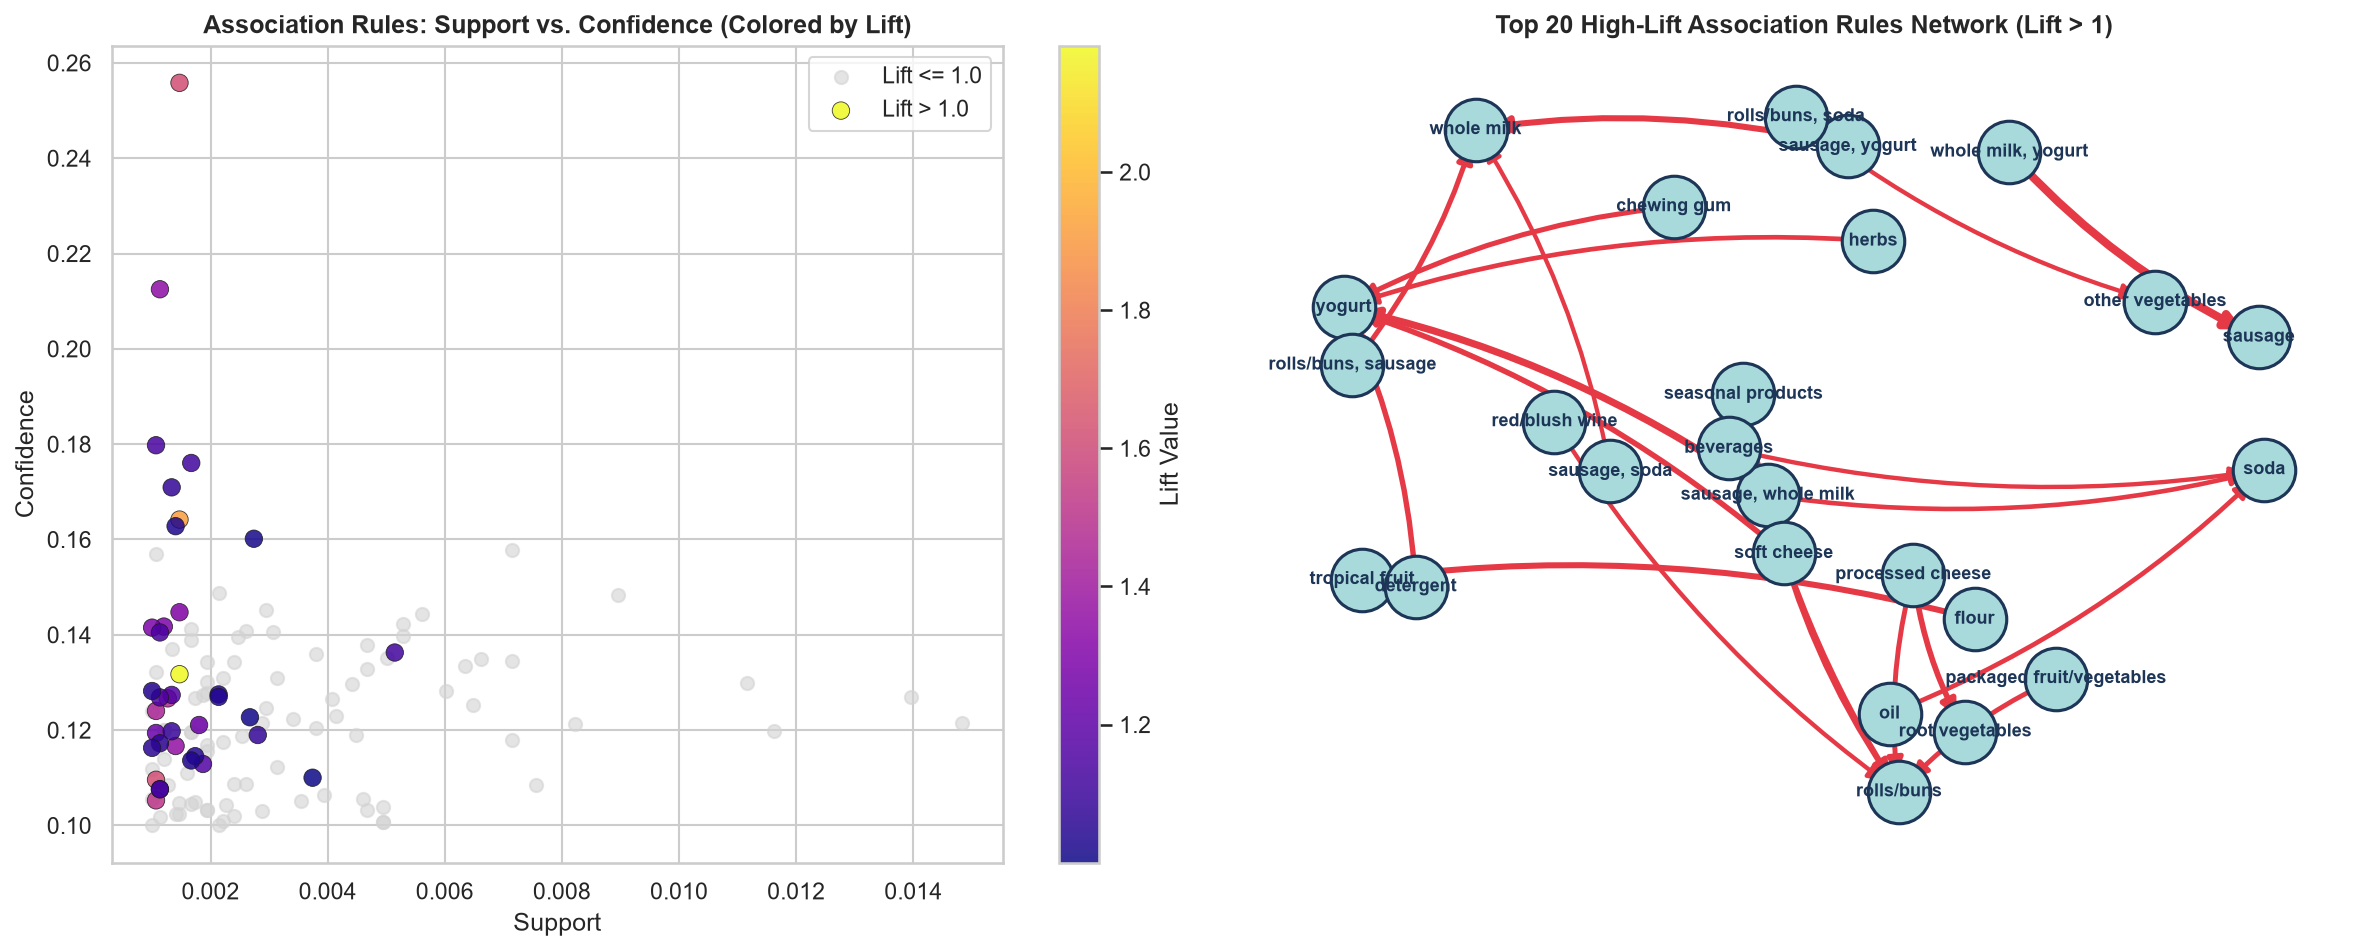

In [7]:
fig4 = plot_rules_distribution(all_rules, OUTPUT_FIGURES_DIR)
display(Image(filename=str(fig4)))

In [8]:
print('=== ĐỀ XUẤT CHIẾN LƯỢC BÁN CHÉO (CROSS-SELLING & BUNDLING) ===')
display(recommend_cross_selling(rules_lift_gt1, top_n=10))

print('=== ĐỀ XUẤT CHIẾN LƯỢC BỐ TRÍ QUẦY KỆ (STORE LAYOUT) ===')
display(recommend_store_layout(rules_lift_gt1, top_n=10))

rule_str,support,confidence,lift,business_action
"whole milk, yogurt -> sausage",0.001470,0.131737,2.182917,"Combo/Bundle: Khi khách mua [whole milk, yogurt], có 13.2% khả năng mua thêm [sausage] (Lift=2.18). Đề xuất gói combo giảm giá 5-10%."
"sausage, whole milk -> yogurt",0.001470,0.164179,1.911760,"Combo/Bundle: Khi khách mua [sausage, whole milk], có 16.4% khả năng mua thêm [yogurt] (Lift=1.91). Đề xuất gói combo giảm giá 5-10%."
"sausage, yogurt -> whole milk",0.001470,0.255814,1.619866,"Combo/Bundle: Khi khách mua [sausage, yogurt], có 25.6% khả năng mua thêm [whole milk] (Lift=1.62). Đề xuất gói combo giảm giá 5-10%."
flour -> tropical fruit,0.001069,0.109589,1.617141,"Cross-sell/Voucher: Khi khách chọn [flour], gợi ý mua kèm [tropical fruit] (Confidence=11.0%, Lift=1.62)."
processed cheese -> root vegetables,0.001069,0.105263,1.513019,"Cross-sell/Voucher: Khi khách chọn [processed cheese], gợi ý mua kèm [root vegetables] (Confidence=10.5%, Lift=1.51)."
soft cheese -> yogurt,0.001270,0.126667,1.474952,"Cross-sell/Voucher: Khi khách chọn [soft cheese], gợi ý mua kèm [yogurt] (Confidence=12.7%, Lift=1.47)."
detergent -> yogurt,0.001069,0.124031,1.444261,"Cross-sell/Voucher: Khi khách chọn [detergent], gợi ý mua kèm [yogurt] (Confidence=12.4%, Lift=1.44)."
chewing gum -> yogurt,0.001403,0.116667,1.358508,"Cross-sell/Voucher: Khi khách chọn [chewing gum], gợi ý mua kèm [yogurt] (Confidence=11.7%, Lift=1.36)."
"rolls/buns, sausage -> whole milk",0.001136,0.212500,1.345594,"Combo/Bundle: Khi khách mua [rolls/buns, sausage], có 21.2% khả năng mua thêm [whole milk] (Lift=1.35). Đề xuất gói combo giảm giá 5-10%."
processed cheese -> rolls/buns,0.001470,0.144737,1.315734,"Cross-sell/Voucher: Khi khách chọn [processed cheese], gợi ý mua kèm [rolls/buns] (Confidence=14.5%, Lift=1.32)."


antecedents,consequents,support,confidence,lift,layout_strategy,rationale
"whole milk, yogurt",sausage,0.00147,0.1317,2.1829,Anchor Placement (Đặt cách xa / Đầu-Cuối hành lang),"Tần suất mua chung cao (Support=0.0015, Lift=2.18). Đặt [whole milk, yogurt] và [sausage] ở hai đầu lối đi để kéo luồng khách di chuyển qua các kệ hàng biên lợi nhuận cao."
"sausage, whole milk",yogurt,0.00147,0.1642,1.9118,Anchor Placement (Đặt cách xa / Đầu-Cuối hành lang),"Tần suất mua chung cao (Support=0.0015, Lift=1.91). Đặt [sausage, whole milk] và [yogurt] ở hai đầu lối đi để kéo luồng khách di chuyển qua các kệ hàng biên lợi nhuận cao."
"sausage, yogurt",whole milk,0.00147,0.2558,1.6199,Anchor Placement (Đặt cách xa / Đầu-Cuối hành lang),"Tần suất mua chung cao (Support=0.0015, Lift=1.62). Đặt [sausage, yogurt] và [whole milk] ở hai đầu lối đi để kéo luồng khách di chuyển qua các kệ hàng biên lợi nhuận cao."
flour,tropical fruit,0.00107,0.1096,1.6171,Complementary Co-location (Đặt kệ kế cận / Cross-merchandising),"Độ liên kết bổ trợ mạnh (Lift=1.62, Confidence=11.0%). Trưng bày [tropical fruit] ngay cạnh quầy [flour] để kích thích mua ngẫu hứng (Impulse Buying)."
processed cheese,root vegetables,0.00107,0.1053,1.5130,Complementary Co-location (Đặt kệ kế cận / Cross-merchandising),"Độ liên kết bổ trợ mạnh (Lift=1.51, Confidence=10.5%). Trưng bày [root vegetables] ngay cạnh quầy [processed cheese] để kích thích mua ngẫu hứng (Impulse Buying)."
soft cheese,yogurt,0.00127,0.1267,1.4750,Complementary Co-location (Đặt kệ kế cận / Cross-merchandising),"Độ liên kết bổ trợ mạnh (Lift=1.47, Confidence=12.7%). Trưng bày [yogurt] ngay cạnh quầy [soft cheese] để kích thích mua ngẫu hứng (Impulse Buying)."
detergent,yogurt,0.00107,0.1240,1.4443,Complementary Co-location (Đặt kệ kế cận / Cross-merchandising),"Độ liên kết bổ trợ mạnh (Lift=1.44, Confidence=12.4%). Trưng bày [yogurt] ngay cạnh quầy [detergent] để kích thích mua ngẫu hứng (Impulse Buying)."
chewing gum,yogurt,0.00140,0.1167,1.3585,Complementary Co-location (Đặt kệ kế cận / Cross-merchandising),"Độ liên kết bổ trợ mạnh (Lift=1.36, Confidence=11.7%). Trưng bày [yogurt] ngay cạnh quầy [chewing gum] để kích thích mua ngẫu hứng (Impulse Buying)."
"rolls/buns, sausage",whole milk,0.00114,0.2125,1.3456,Complementary Co-location (Đặt kệ kế cận / Cross-merchandising),"Độ liên kết bổ trợ mạnh (Lift=1.35, Confidence=21.2%). Trưng bày [whole milk] ngay cạnh quầy [rolls/buns, sausage] để kích thích mua ngẫu hứng (Impulse Buying)."
processed cheese,rolls/buns,0.00147,0.1447,1.3157,Anchor Placement (Đặt cách xa / Đầu-Cuối hành lang),"Tần suất mua chung cao (Support=0.0015, Lift=1.32). Đặt [processed cheese] và [rolls/buns] ở hai đầu lối đi để kéo luồng khách di chuyển qua các kệ hàng biên lợi nhuận cao."
